# Part 1: Data Understanding and Data Cleansing
**Project:** Semiconductor yield (Pass/Fail) prediction from sensor signals
**Scope of this notebook:** Step 1 (import and explore) and Step 2 (data cleansing). Its output, `sensor_cleaned.csv`, is the hand-off file for the EDA, modelling and conclusion parts.

Place `sensor-data.csv` in the same folder. Needs only pandas, numpy, matplotlib, seaborn, scipy.

In [1]:
import pandas as pd
df = pd.read_csv(r"C:\Users\Lenovo\Downloads\signal-data.csv")
print(df.shape)
print(df.columns[:3].tolist(), df.columns[-2:].tolist())

(1567, 592)
['Time', '0', '1'] ['589', 'Pass/Fail']


In [2]:
FILE = r"C:\Users\Lenovo\Downloads\signal-data.csv"

In [3]:
import os
os.chdir(r"C:\Users\Lenovo\Downloads")
FILE = "signal-data.csv"

In [4]:
import os
print(os.getcwd())

C:\Users\Lenovo\Downloads


In [5]:
import os
os.chdir(r"C:\Users\Lenovo\Downloads")

In [6]:
import pandas as pd
df = pd.read_csv("signal-data.csv")
print(df.shape)
print(df.columns[:3].tolist(), df.columns[-2:].tolist())

(1567, 592)
['Time', '0', '1'] ['589', 'Pass/Fail']


In [7]:
%pip install seaborn scipy matplotlib

Note: you may need to restart the kernel to use updated packages.


In [8]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
sns.set_style("whitegrid")
pd.set_option("display.max_columns", 30)
FILE = "sensor-data.csv"

## 1. Import and explore the data

### 1.1 Load and first look

In [9]:
df = pd.read_csv(FILE)
print("Shape (rows, columns):", df.shape)
display(df.head())
display(df.tail(3))

Shape (rows, columns): (1567, 592)


,Time,0,1,2,3,4,5,6,7,8,9,10,11,12,13,...,576,577,578,579,580,581,582,583,584,585,586,587,588,589,Pass/Fail
0,19/07/2008 11:55:00,3030.93,2564.00,2187.7333,1411.1265,1.3602,100.0,97.6133,0.1242,1.5005,0.0162,-0.0034,0.9455,202.4396,0.0,...,1.6765,14.9509,NaN,NaN,NaN,NaN,0.5005,0.0118,0.0035,2.3630,NaN,NaN,NaN,NaN,-1
1,19/07/2008 12:32:00,3095.78,2465.14,2230.4222,1463.6606,0.8294,100.0,102.3433,0.1247,1.4966,-0.0005,-0.0148,0.9627,200.5470,0.0,...,1.1065,10.9003,0.0096,0.0201,0.0060,208.2045,0.5019,0.0223,0.0055,4.4447,0.0096,0.0201,0.0060,208.2045,-1
2,19/07/2008 13:17:00,2932.61,2559.94,2186.4111,1698.0172,1.5102,100.0,95.4878,0.1241,1.4436,0.0041,0.0013,0.9615,202.0179,0.0,...,2.0952,9.2721,0.0584,0.0484,0.0148,82.8602,0.4958,0.0157,0.0039,3.1745,0.0584,0.0484,0.0148,82.8602,1
3,19/07/2008 14:43:00,2988.72,2479.90,2199.0333,909.7926,1.3204,100.0,104.2367,0.1217,1.4882,-0.0124,-0.0033,0.9629,201.8482,0.0,...,1.7585,8.5831,0.0202,0.0149,0.0044,73.8432,0.4990,0.0103,0.0025,2.0544,0.0202,0.0149,0.0044,73.8432,-1
4,19/07/2008 15:22:00,3032.24,2502.87,2233.3667,1326.5200,1.5334,100.0,100.3967,0.1235,1.5031,-0.0031,-0.0072,0.9569,201.9424,0.0,...,1.6597,10.9698,NaN,NaN,NaN,NaN,0.4800,0.4766,0.1045,99.3032,0.0202,0.0149,0.0044,73.8432,-1


,Time,0,1,2,3,4,5,6,7,8,9,10,11,12,13,...,576,577,578,579,580,581,582,583,584,585,586,587,588,589,Pass/Fail
1564,17/10/2008 05:26:00,2978.81,2379.78,2206.3000,1110.4967,0.8236,100.0,99.4122,0.1208,NaN,NaN,NaN,NaN,NaN,NaN,...,1.2237,17.7267,0.0197,0.0086,0.0025,43.5231,0.4987,0.0153,0.0041,3.0590,0.0197,0.0086,0.0025,43.5231,-1
1565,17/10/2008 06:01:00,2894.92,2532.01,2177.0333,1183.7287,1.5726,100.0,98.7978,0.1213,1.4622,-0.0072,0.0032,0.9694,197.2448,0.0,...,1.7085,19.2104,0.0262,0.0245,0.0075,93.4941,0.5004,0.0178,0.0038,3.5662,0.0262,0.0245,0.0075,93.4941,-1
1566,17/10/2008 06:07:00,2944.92,2450.76,2195.4444,2914.1792,1.5978,100.0,85.1011,0.1235,NaN,NaN,NaN,NaN,NaN,NaN,...,1.2878,22.9183,0.0117,0.0162,0.0045,137.7844,0.4987,0.0181,0.0040,3.6275,0.0117,0.0162,0.0045,137.7844,-1


In [10]:
print("Column dtypes:"); print(df.dtypes.value_counts())
non_num = df.select_dtypes(exclude="number").columns.tolist()
print("\nNon-numeric columns:", non_num)
print("First 5 / last 3 column names:", df.columns[:5].tolist(), df.columns[-3:].tolist())
print("\nMemory: %.2f MB" % (df.memory_usage(deep=True).sum()/1e6))

Column dtypes:
float64    590
str          1
int64        1
Name: count, dtype: int64

Non-numeric columns: ['Time']
First 5 / last 3 column names: ['Time', '0', '1', '2', '3'] ['588', '589', 'Pass/Fail']

Memory: 7.52 MB


**Comment:** The file has one `Time` column (text), 590 numeric sensor columns and the `Pass/Fail` label. Sensor names are anonymous numbers, so we cannot use physical meaning; decisions must rely on statistics and general process logic.

### 1.2 Timestamp and target checks

Unparseable timestamps: 0
Time range: 2008-07-19 11:55:00 to 2008-10-17 06:07:00 | span: 89 days 18:12:00
Is data sorted by time? True
Duplicate timestamps: 33

Target values: [np.int64(-1), np.int64(1)]
Pass/Fail
-1    1463
 1     104
Name: count, dtype: int64
Pass/Fail
-1    93.36 %
 1     6.64 %
Name: count, dtype: str


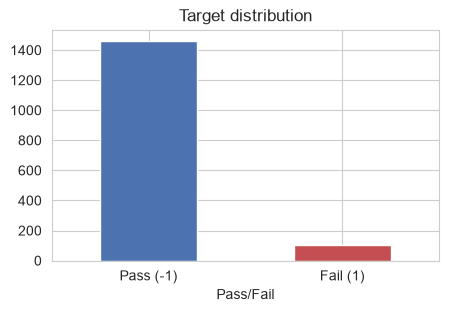

In [11]:
df["Time"] = pd.to_datetime(df["Time"], errors="coerce")
print("Unparseable timestamps:", df["Time"].isna().sum())
print("Time range:", df["Time"].min(), "to", df["Time"].max(), "| span:", df["Time"].max()-df["Time"].min())
print("Is data sorted by time?", df["Time"].is_monotonic_increasing)
print("Duplicate timestamps:", df["Time"].duplicated().sum())

print("\nTarget values:", sorted(df["Pass/Fail"].unique()))
vc = df["Pass/Fail"].value_counts()
print(vc); print((vc/len(df)*100).round(2).astype(str)+" %")
vc.rename({-1:"Pass (-1)",1:"Fail (1)"}).plot(kind="bar", color=["#4c72b0","#c44e52"], figsize=(5,3), title="Target distribution")
plt.xticks(rotation=0); plt.show()

**Comment:** `-1` = Pass and `1` = Fail. Fails are only about 6-7% of rows, so the target is heavily imbalanced (this matters for modelling, and is why accuracy alone will be misleading). Timestamps show the period covered; if rows are not time-sorted we should sort them before any time-based analysis.

### 1.3 Missing values

Total missing cells: 41951 (4.54% of all sensor cells)
Columns with any missing : 538 of 590
Columns with > 5% missing: 52
Columns with > 20% missing: 32
Columns with > 40% missing: 32
Columns with > 50% missing: 28
Columns with > 80% missing: 8


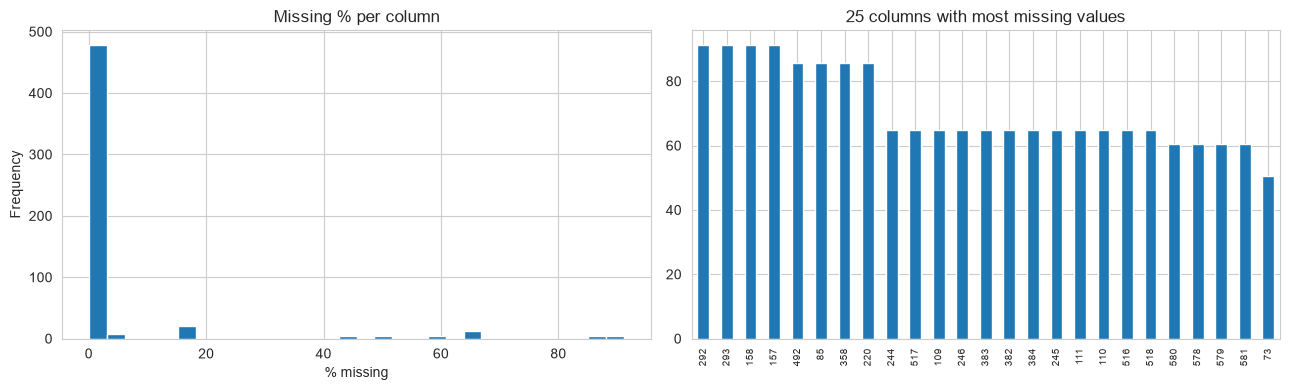


Rows: max missing 25.8%, mean 4.5%; rows with >50% missing: 0


In [12]:
sens = [c for c in df.columns if c not in ["Time","Pass/Fail"]]
miss_col = df[sens].isna().mean()*100
print("Total missing cells: %d (%.2f%% of all sensor cells)" % (df[sens].isna().sum().sum(), df[sens].isna().values.mean()*100))
print("Columns with any missing :", (miss_col>0).sum(), "of", len(sens))
for t in [5,20,40,50,80]:
    print(f"Columns with > {t}% missing: {(miss_col>t).sum()}")

fig, ax = plt.subplots(1,2, figsize=(13,4))
miss_col[miss_col>0].plot(kind="hist", bins=30, ax=ax[0]); ax[0].set_title("Missing % per column"); ax[0].set_xlabel("% missing")
miss_col.sort_values(ascending=False).head(25).plot(kind="bar", ax=ax[1]); ax[1].set_title("25 columns with most missing values"); ax[1].tick_params(axis="x", labelsize=7)
plt.tight_layout(); plt.show()

miss_row = df[sens].isna().mean(axis=1)*100
print("\nRows: max missing %.1f%%, mean %.1f%%; rows with >50%% missing: %d" % (miss_row.max(), miss_row.mean(), (miss_row>50).sum()))

fail
Pass    4.55
Fail    4.32
Name: row_missing_%, dtype: float64
Mann-Whitney p-value (missing % Pass vs Fail): 0.3477


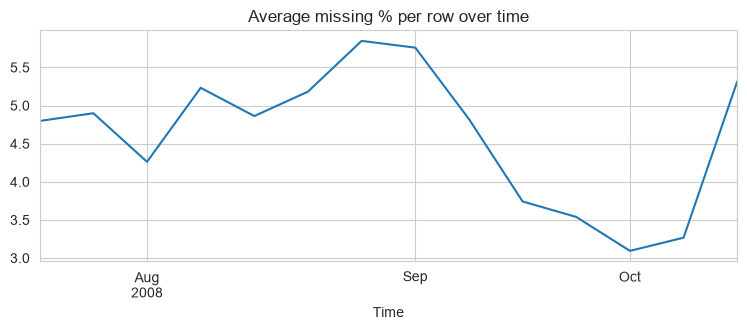

In [13]:
# Is missingness related to the outcome or to time? (if yes, it is informative - dropping/filling blindly could hide signal)
tmp = pd.DataFrame({"row_missing_%":miss_row, "fail":(df["Pass/Fail"]==1).astype(int), "Time":df["Time"]})
print(tmp.groupby("fail")["row_missing_%"].mean().round(2).rename({0:"Pass",1:"Fail"}))
p = stats.mannwhitneyu(tmp.loc[tmp.fail==0,"row_missing_%"], tmp.loc[tmp.fail==1,"row_missing_%"]).pvalue
print("Mann-Whitney p-value (missing %% Pass vs Fail): %.4f" % p)
tmp.set_index("Time")["row_missing_%"].resample("W").mean().plot(figsize=(9,3), title="Average missing % per row over time"); plt.show()

**Comment:** Missing data is widespread but concentrated: a small group of columns is mostly empty while most others have only a few gaps. The row-level plot and test tell us whether missing values are random or linked to time / failures. Columns that are mostly empty cannot be reliably filled, which drives the drop rule in Section 2.

### 1.4 Constant / near-constant sensors, duplicates, summary statistics

In [14]:
nun = df[sens].nunique(dropna=True)
print("Constant columns (<=1 unique value):", (nun<=1).sum())
print("Columns with <=5 unique values     :", (nun<=5).sum())
top_freq = df[sens].apply(lambda s: s.value_counts(normalize=True, dropna=True).iloc[0] if s.notna().any() else 1.0)
print("Columns where one value is >=99%% of non-missing rows: %d" % (top_freq>=0.99).sum())
print("Duplicate full rows:", df.duplicated().sum())

Constant columns (<=1 unique value): 116
Columns with <=5 unique values     : 122
Columns where one value is >=99% of non-missing rows: 122
Duplicate full rows: 0


In [15]:
desc = df[sens].describe().T
desc["skew"] = df[sens].skew(); desc["missing_%"] = miss_col
display(desc.sort_values("std", ascending=False).head(8))
display(desc.sort_values("skew", key=abs, ascending=False).head(8))
print("Sensors with |skew|>1: %d of %d" % ((desc['skew'].abs()>1).sum(), len(sens)))
print("Scale range: smallest std %.2e, largest std %.2e" % (desc['std'].min(), desc['std'].max()))

,count,mean,std,min,25%,50%,75%,max,skew,missing_%
162,1565.0,4797.154633,6553.569317,0.00,451.0000,1784.0000,6384.0000,36871.0000,1.828761,0.127632
161,1565.0,4066.850479,4239.245058,0.00,1321.0000,2614.0000,5034.0000,37943.0000,2.229785,0.127632
297,1565.0,2342.826978,3226.924298,0.00,210.9366,820.0988,3190.6164,18520.4683,1.790486,0.127632
24,1565.0,-298.598136,2902.690117,-14804.50,-1476.0000,-78.7500,1377.2500,14106.0000,-0.054091,0.127632
296,1565.0,1879.228369,1975.111365,0.00,603.0329,1202.4121,2341.2887,15559.9525,2.189508,0.127632
23,1565.0,-3806.299734,1380.162148,-9986.75,-4371.7500,-3820.7500,-3352.7500,2363.0000,0.356647,0.127632
159,1565.0,882.680511,983.043021,0.00,411.0000,623.0000,966.0000,7791.0000,4.203623,0.127632
21,1565.0,-5618.393610,626.822178,-7150.25,-5933.2500,-5523.2500,-5356.2500,0.0000,2.374624,0.127632


,count,mean,std,min,25%,50%,75%,max,skew,missing_%
390,1567.0,1.431868,20.326415,0.3046,0.675150,0.87730,1.148200,805.3936,39.562779,0.000000
252,1567.0,4.645115,64.354756,0.7673,2.205650,2.86460,3.795050,2549.9885,39.560364,0.000000
287,1564.0,0.367529,7.386343,0.0513,0.114875,0.13895,0.198450,292.2274,39.521337,0.191449
152,1564.0,1.196733,23.364063,0.1544,0.373750,0.46870,0.679925,924.3780,39.519611,0.191449
209,1561.0,0.029564,1.168074,0.0000,0.000000,0.00000,0.000000,46.1500,39.509493,0.382897
74,1561.0,0.002688,0.106190,0.0000,0.000000,0.00000,0.000000,4.1955,39.509493,0.382897
478,1561.0,0.128123,5.062075,0.0000,0.000000,0.00000,0.000000,200.0000,39.509493,0.382897
342,1561.0,0.000286,0.011319,0.0000,0.000000,0.00000,0.000000,0.4472,39.509493,0.382897


Sensors with |skew|>1: 322 of 590
Scale range: smallest std 0.00e+00, largest std 6.55e+03


**Comment:** Constant columns carry no information. Standard deviations span many orders of magnitude, so **scaling is required** later for distance/linear models. Many sensors are strongly skewed with extreme values.

### 1.5 Outlier screening

Sensors with >1% extreme outliers (3xIQR): 158 of 590


,% extreme outliers
31,22.619808
40,15.230071
312,12.771392
116,12.252712
523,11.104020
251,10.976388
389,10.848756
519,9.624413
247,9.154930
448,8.620690


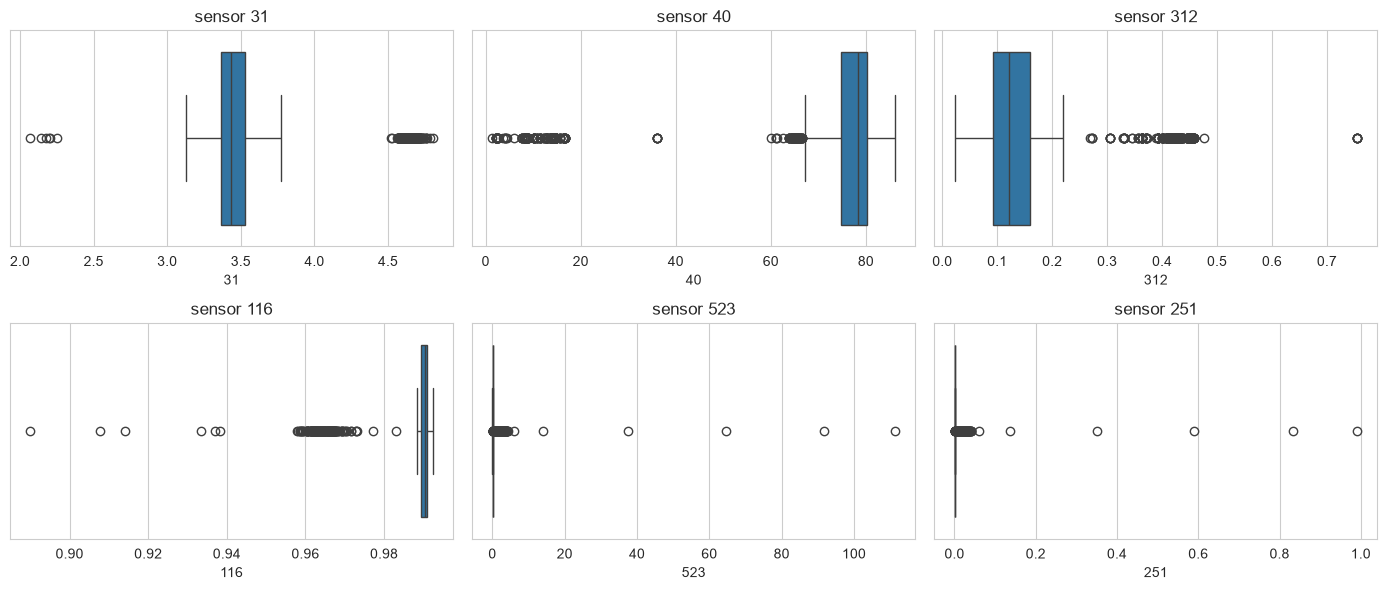

In [16]:
def iqr_outlier_share(s):
    s = s.dropna(); q1,q3 = s.quantile([.25,.75]); i = q3-q1
    return 0 if i==0 else ((s<q1-3*i)|(s>q3+3*i)).mean()*100      # 3xIQR = extreme outliers only
out = df[sens].apply(iqr_outlier_share).sort_values(ascending=False)
print("Sensors with >1%% extreme outliers (3xIQR): %d of %d" % ((out>1).sum(), len(sens)))
display(out.head(10).to_frame("% extreme outliers"))
worst = out.head(6).index
fig, ax = plt.subplots(2,3, figsize=(14,6))
for a,c in zip(ax.ravel(), worst): sns.boxplot(x=df[c], ax=a); a.set_title(f"sensor {c}")
plt.tight_layout(); plt.show()

**Comment:** Extreme values exist in a lot of sensors. In process monitoring these can be genuine excursions (which are exactly what we want to detect) or sensor glitches. Without domain labels for sensor limits we cannot tell them apart, so we **keep outliers** and rely on robust choices (median imputation, scaling, tree models) instead of deleting rows.

## 2. Data cleansing

### Cleaning rules (justification)
| # | Action | Reason |
|---|---|---|
| 1 | Parse `Time`, sort chronologically | Correct dtype, needed for drift analysis |
| 2 | Drop constant sensors | Zero variance = zero information, cannot separate Pass from Fail |
| 3 | Drop sensors with >40% missing | Imputing that many values would mostly invent data |
| 4 | Drop duplicate rows | Duplicates over-weight some units |
| 5 | Drop highly correlated sensors (\|r\|>0.95), keep one | Redundant information, unstable models, more noise |
| 6 | Drop `Time` as a feature | It is an identifier, not a physical signal (kept in a separate file for time analysis) |
| 7 | Recode target: Fail=1, Pass=0 | Standard convention, minority class as positive |
| 8 | Impute remaining missing values with the median | Sensors are skewed with outliers, so the median is more robust than the mean |
| 9 | Keep outliers | Possible real excursions (see 1.5) |

In [17]:
log = []                                    # audit trail of every cleaning step
def record(step, before, after): log.append({"step":step, "columns_before":before, "columns_after":after})

dfc = df.sort_values("Time").reset_index(drop=True)
sensors = sens.copy(); n0 = len(sensors)

# 2. constant sensors
const_cols = [c for c in sensors if dfc[c].nunique(dropna=True) <= 1]
sensors = [c for c in sensors if c not in const_cols]; record("Drop constant sensors", n0, len(sensors))

# 3. sparse sensors (>40% missing)
sparse_cols = [c for c in sensors if dfc[c].isna().mean() > 0.40]
sensors = [c for c in sensors if c not in sparse_cols]; record("Drop sensors >40% missing", len(sensors)+len(sparse_cols), len(sensors))

# 4. duplicate rows
rows_before = len(dfc)
dfc = dfc.drop_duplicates(subset=sensors+["Pass/Fail"]).reset_index(drop=True)
print("Duplicate rows removed:", rows_before-len(dfc))

# 5. highly correlated sensors (no target used -> no leakage)
corr = dfc[sensors].corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
corr_cols = [c for c in upper.columns if (upper[c] > 0.95).any()]
sensors = [c for c in sensors if c not in corr_cols]; record("Drop correlated sensors |r|>0.95", len(sensors)+len(corr_cols), len(sensors))

print(pd.DataFrame(log))
print(f"\nDropped: {len(const_cols)} constant, {len(sparse_cols)} sparse, {len(corr_cols)} correlated -> {len(sensors)} sensors kept of {n0}")

Duplicate rows removed: 0
                               step  columns_before  columns_after
0             Drop constant sensors             590            474
1         Drop sensors >40% missing             474            442
2  Drop correlated sensors |r|>0.95             442            269

Dropped: 116 constant, 32 sparse, 173 correlated -> 269 sensors kept of 590


In [18]:
# 7. target recoding
dfc["Fail"] = (dfc["Pass/Fail"]==1).astype(int)
assert set(dfc["Fail"].unique()) <= {0,1}

# 8. median imputation on the kept sensors
remaining_missing = dfc[sensors].isna().sum().sum()
medians = dfc[sensors].median()
dfc_imputed = dfc.copy()
dfc_imputed[sensors] = dfc_imputed[sensors].fillna(medians)
print("Missing cells before imputation:", remaining_missing, "| after:", dfc_imputed[sensors].isna().sum().sum())
assert dfc_imputed[sensors].isna().sum().sum() == 0

Missing cells before imputation: 5020 | after: 0


### 2.1 Did cleaning change the data's character? (validation)

In [19]:
# Imputation should not distort distributions: compare mean/std before vs after for imputed columns
had_na = [c for c in sensors if dfc[c].isna().any()]
chk = pd.DataFrame({"std_before":dfc[had_na].std(), "std_after":dfc_imputed[had_na].std(),
                    "mean_before":dfc[had_na].mean(), "mean_after":dfc_imputed[had_na].mean()})
chk["std_change_%"] = (chk.std_after/chk.std_before-1)*100
print("Imputed columns:", len(had_na)); display(chk["std_change_%"].describe().round(2).to_frame("std change %"))
print("Class balance preserved: before %.2f%% fail | after cleaning %.2f%% fail" %
      ((df['Pass/Fail']==1).mean()*100, dfc['Fail'].mean()*100))

Imputed columns: 244


,std change %
count,244.00
mean,-0.63
std,1.75
min,-8.81
25%,-0.29
50%,-0.19
75%,-0.06
max,-0.02


Class balance preserved: before 6.64% fail | after cleaning 6.64% fail


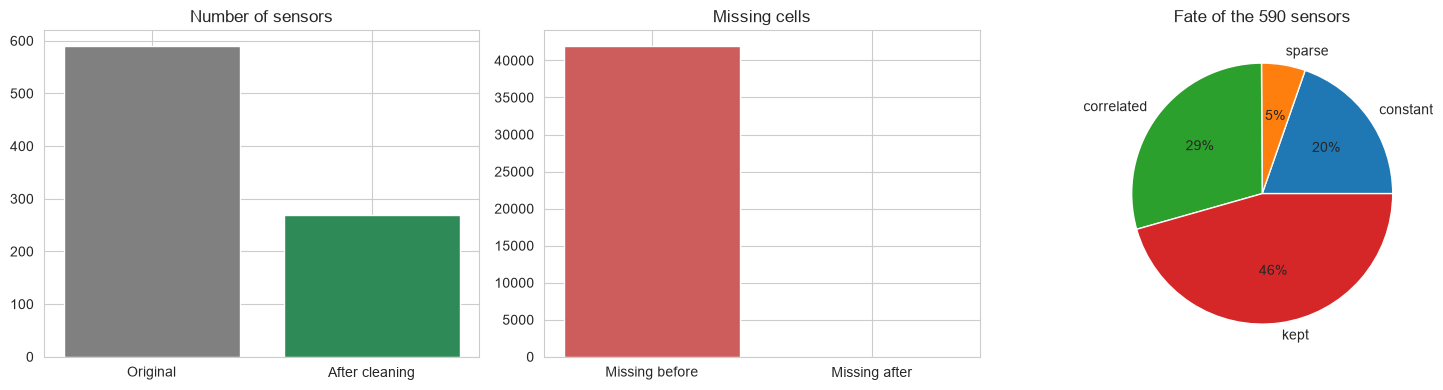

In [20]:
fig, ax = plt.subplots(1,3, figsize=(15,4))
ax[0].bar(["Original","After cleaning"], [len(sens), len(sensors)], color=["gray","seagreen"]); ax[0].set_title("Number of sensors")
ax[1].bar(["Missing before","Missing after"], [df[sens].isna().sum().sum(), dfc_imputed[sensors].isna().sum().sum()], color=["indianred","seagreen"]); ax[1].set_title("Missing cells")
sizes=[len(const_cols),len(sparse_cols),len(corr_cols),len(sensors)]
ax[2].pie(sizes, labels=["constant","sparse","correlated","kept"], autopct="%1.0f%%"); ax[2].set_title("Fate of the 590 sensors")
plt.tight_layout(); plt.show()

**Comment:** Imputation changes column spread only slightly, and the class ratio is unchanged, so cleaning did not distort the data or the label balance. The chart shows how many of the original 590 sensors were redundant or unusable, which already answers part of the project question: *not all features are needed*.

## 3. Export hand-off files for teammates

In [21]:
# A) cleaned but NOT imputed (recommended for modelling: impute inside the CV pipeline after train/test split, avoids leakage)
dfc[["Time"]+sensors+["Fail"]].to_csv("sensor_cleaned_with_nan.csv", index=False)
# B) cleaned AND median-imputed (ready to use for EDA and quick experiments)
dfc_imputed[["Time"]+sensors+["Fail"]].to_csv("sensor_cleaned.csv", index=False)
pd.Series({"constant":const_cols,"sparse":sparse_cols,"correlated":corr_cols}).apply(lambda x: ", ".join(map(str,x))).to_csv("dropped_columns_log.csv", header=["columns"])
print("Saved: sensor_cleaned.csv, sensor_cleaned_with_nan.csv, dropped_columns_log.csv")
print("Final shape:", dfc_imputed[['Time']+sensors+['Fail']].shape)

Saved: sensor_cleaned.csv, sensor_cleaned_with_nan.csv, dropped_columns_log.csv
Final shape: (1567, 271)


## 4. Summary of my part
* Data: 1567 x 592; 590 sensors, one timestamp column, and the Pass/Fail label. The target is imbalanced: 104 fails and 1463 passes, a 6.64% fail rate.
Problems found: many missing values (a subset of columns almost entirely empty), constant sensors, heavily skewed features with extreme outliers, sensors on very different scales, and redundant correlated sensors.
* Actions: dropped 116 constant sensors, 32 sensors with more than 40% missing values, and 173 sensors correlated above 0.95 with another, leaving 269 of the original 590 sensors. No duplicate rows were found. Remaining gaps were filled with the median. Target was recoded to Fail (1 = fail, 0 = pass). Outliers were kept, since in process monitoring they may be genuine excursions rather than errors.
* Validation: median imputation barely changed each column's spread (mean std change of about -0.6% across the 244 imputed columns), and the class balance was unchanged after cleaning (6.64% fail before and after). This confirms cleaning did not distort the data.
* Hand-off: sensor_cleaned.csv (target column Fail: 1 = fail, 0 = pass). Modelling teammates should note that imputing on the full dataset carries a small leakage risk; sensor_cleaned_with_nan.csv lets them impute after the train/test split instead.
* Passed to next steps: scaling is needed given the different sensor scales, class imbalance must be handled (SMOTE or class weights), and F1/recall of the Fail class should be used instead of accuracy.